# Does late delivery lower repeat purchase and reviews?

**Question.** Olist customers rarely return. Is late delivery a material cause?

**Design.** One row per customer, using their first order. Follow-up starts at delivery, since that is when a customer experiences lateness. A customer enters the repeat analysis only if a full 180 days of data exists after delivery, so recent buyers are not miscounted as lost. Review score is not used as a control because it sits between lateness and repeat purchase.

**Reading the result.** This is observational. It estimates an association after controls, not a proven causal effect. Eligibility depends on delivery date, so the study under-represents late orders from early 2018 (see README).

In [1]:
import warnings; warnings.filterwarnings('ignore')
import json, os
import numpy as np, pandas as pd, psycopg2, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from scipy import stats
pd.set_option('display.width',140)
plt.rcParams.update({'figure.dpi':130,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'axes.axisbelow':True,'grid.color':'#e6e6e3','font.size':10})
INK,ACC,MUTE='#2b2b2b','#20808D','#9a9a94'
os.makedirs('../outputs/charts',exist_ok=True)
def save_metrics(key,val):
    p='../outputs/metrics.json'; m=json.load(open(p)) if os.path.exists(p) else {}
    m[key]=val; json.dump(m,open(p,'w'),indent=2,default=float)


In [2]:
con=psycopg2.connect(dbname='olist')
d=pd.read_sql("select * from analytics.delivery_cohort",con)
print('Delivered first orders:',len(d)); print('With full 180 days:',int(d.eligible_180d.sum()))
print('Reordered before first delivery (excluded):',int((d.eligible_180d&d.reordered_before_delivery).sum()))
s=d[d.eligible_180d & ~d.reordered_before_delivery & d.installments.notna()].copy()
s['y']=s.repeat_180d.astype(int); s['late']=s.is_late.astype(int)
top=s.category.value_counts().index[:15]; s['cat']=s.category.where(s.category.isin(top),'other')
s['log_gmv']=np.log(s.gmv); s['log_freight']=np.log1p(s.freight); s['same_state']=(s.customer_state==s.seller_state).astype(int)
s['month']=s.purchase_month.astype(str); s['state']=s.customer_state; s['pay']=s.payment_type.fillna('other')
print('Analysis sample:',len(s))

Delivered first orders: 93294
With full 180 days: 50930
Reordered before first delivery (excluded): 141
Analysis sample: 50788


## 1. Raw comparison

In [3]:
rows=[]
for g,x in s.groupby('late'):
    lo,hi=proportion_confint(x.y.sum(),len(x),method='wilson'); rows.append(dict(group='Late' if g else 'On time',customers=len(x),repeaters=x.y.sum(),repeat_pct=100*x.y.mean(),ci_low=100*lo,ci_high=100*hi))
raw=pd.DataFrame(rows); display(raw)
tab=[[s[s.late==1].y.sum(),(s.late==1).sum()-s[s.late==1].y.sum()],[s[s.late==0].y.sum(),(s.late==0).sum()-s[s.late==0].y.sum()]]
fisher=stats.fisher_exact(tab)[1]; print('Fisher exact p =',round(fisher,4))
p0=s[s.late==0].y.mean(); n1=(s.late==1).sum(); n0=(s.late==0).sum()
se=np.sqrt(p0*(1-p0)*(1/n1+1/n0)); mde=2.8*se; print(f'Smallest gap detectable with 80% power: {100*mde:.2f} points')

,group,customers,repeaters,repeat_pct,ci_low,ci_high
0,On time,48247,880,1.823948,1.708321,1.947245
1,Late,2541,35,1.377410,0.992065,1.909549


Fisher exact p = 0.1076
Smallest gap detectable with 80% power: 0.76 points


## 2. Adjusted estimates

Four specifications test the same question. Standard errors cluster by seller, since orders from one seller share operations.

- **A. Linear probability model** with category, state, month, payment and order controls
- **B. Logit average marginal effect** with coarser controls so the model converges on a rare outcome
- **C. Near-promise comparison**, within 3 days of the promised date, where late and on-time orders are most alike. It controls for days from the promise date, so it is noisy
- **D. Seller fixed effects**, comparing orders within the same seller

In [4]:
ctrl='log_gmv + log_freight + n_items + promised_days + same_state + installments + C(cat) + C(state) + C(month) + C(pay)'
cl=lambda df:{'groups':df.seller_id.astype('category').cat.codes}
res=[]
def add(name,est,lo,hi,p,n): res.append(dict(model=name,estimate_pts=100*est,ci_low=100*lo,ci_high=100*hi,p_value=p,n=n))
m=smf.ols('y ~ late + '+ctrl,s).fit(cov_type='cluster',cov_kwds=cl(s)); ci=m.conf_int().loc['late']; add('A. Linear, full controls',m.params['late'],ci[0],ci[1],m.pvalues['late'],len(s))
region={'SP':'SE','RJ':'SE','MG':'SE','ES':'SE','PR':'S','SC':'S','RS':'S','DF':'CW','GO':'CW','MT':'CW','MS':'CW'}
s['region']=s.state.map(region).fillna('N_NE'); s['qtr']=pd.PeriodIndex(pd.to_datetime(s.purchase_month),freq='Q').astype(str)
s['cat8']=s.category.where(s.category.isin(s.category.value_counts().index[:8]),'other')
lg=smf.logit('y ~ late + log_gmv + log_freight + n_items + promised_days + same_state + C(cat8) + C(region) + C(qtr)',s).fit(disp=0,maxiter=500,method='lbfgs',cov_type='cluster',cov_kwds=cl(s))
print('Logit converged:',lg.mle_retvals.get('converged'))
a=lg.get_margeff().summary_frame().loc['late']; add('B. Logit marginal effect',a.iloc[0],a.iloc[4],a.iloc[5],a.iloc[3],len(s))
n=s[s.days_late.between(-3,3)].copy()
m=smf.ols('y ~ late + days_late + log_gmv + log_freight + n_items + promised_days + same_state + C(region) + C(qtr)',n).fit(cov_type='cluster',cov_kwds=cl(n)); ci=m.conf_int().loc['late']; add('C. Near promise date (+/-3 days)',m.params['late'],ci[0],ci[1],m.pvalues['late'],len(n))
import patsy
y,X=patsy.dmatrices('y ~ late + log_gmv + log_freight + n_items + promised_days + same_state + installments + C(cat) + C(state) + C(month) + C(pay)',s,return_type='dataframe')
X=X.drop(columns='Intercept'); g=s.seller_id.values
dy=y-y.groupby(g).transform('mean'); dX=X-X.groupby(g).transform('mean')
import statsmodels.api as sm
keep=dX.columns[dX.std()>0]; m=sm.OLS(dy,dX[keep]).fit(cov_type='cluster',cov_kwds=cl(s)); ci=m.conf_int().loc['late']; add('D. Seller fixed effects',m.params['late'],ci[0],ci[1],m.pvalues['late'],len(s))
models=pd.DataFrame(res); display(models.round(3))
models.to_csv('../outputs/tables/late_repeat_models.csv',index=False)

Logit converged: True


,model,estimate_pts,ci_low,ci_high,p_value,n
0,"A. Linear, full controls",-0.333,-0.796,0.131,0.159,50788
1,B. Logit marginal effect,-0.419,-1.023,0.185,0.174,50788
2,C. Near promise date (+/-3 days),0.437,-1.667,2.541,0.684,2953
3,D. Seller fixed effects,-0.290,-0.765,0.185,0.231,50788


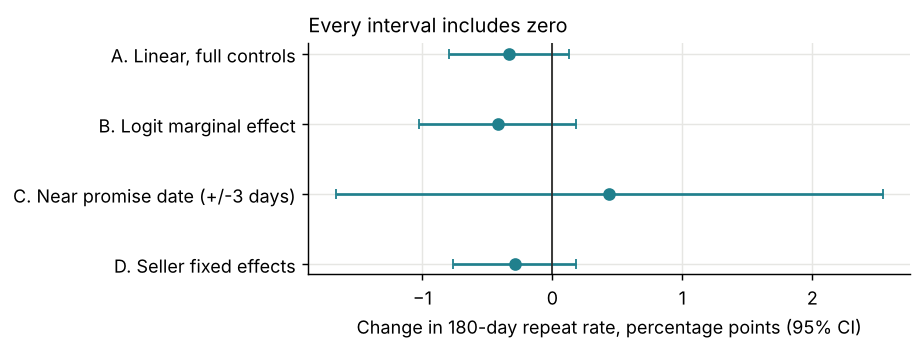

In [5]:
fig,ax=plt.subplots(figsize=(7.2,2.8)); yy=range(len(models))[::-1]
ax.errorbar(models.estimate_pts,yy,xerr=[models.estimate_pts-models.ci_low,models.ci_high-models.estimate_pts],fmt='o',color=ACC,capsize=3)
ax.axvline(0,color=INK,lw=1); ax.set_yticks(list(yy)); ax.set_yticklabels(models.model); ax.set_xlabel('Change in 180-day repeat rate, percentage points (95% CI)')
ax.set_title('Every interval includes zero',loc='left',fontsize=11); plt.tight_layout(); plt.savefig('../outputs/charts/late_repeat_models.png'); plt.show()

## 3. Is on-time, 5-star service enough?

If repeat stays near 2% for the best experiences, delivery cannot be the main retention constraint.

In [6]:
exp=s.dropna(subset=['review_score']).copy()
exp['group']=np.select([(exp.late==0)&(exp.review_score==5),(exp.late==0)&(exp.review_score<=2),(exp.late==1)],['On time, 5 stars','On time, 1-2 stars','Late, any score'],'Other')
t=exp[exp.group!='Other'].groupby('group').y.agg(customers='size',repeaters='sum',repeat_pct=lambda v:100*v.mean()).reset_index(); display(t.round(2))
t.to_csv('../outputs/tables/repeat_by_experience.csv',index=False)
sc=exp.groupby('review_score').y.agg(customers='size',repeaters='sum',repeat_pct=lambda v:100*v.mean()).round(2); display(sc)
sc.to_csv('../outputs/tables/repeat_by_review.csv')
s365=d[d.eligible_365d & ~d.reordered_before_delivery]
t365=s365.groupby('is_late').repeat_365d.agg(['size','sum','mean']); display(t365)
print('Fisher p, 365d:',round(stats.fisher_exact([[t365.loc[True,'sum'],t365.loc[True,'size']-t365.loc[True,'sum']],[t365.loc[False,'sum'],t365.loc[False,'size']-t365.loc[False,'sum']]])[1],3))

,group,customers,repeaters,repeat_pct
0,"Late, any score",2473,35,1.42
1,"On time, 1-2 stars",4464,70,1.57
2,"On time, 5 stars",29429,566,1.92


,customers,repeaters,repeat_pct
review_score,,,
1.0,4437,68,1.53
2.0,1552,20,1.29
3.0,4349,76,1.75
4.0,10213,169,1.65
5.0,29868,577,1.93


,size,sum,mean
is_late,,,
False,18374,580,0.031566
True,557,12,0.021544


Fisher p, 365d: 0.216


## 4. Late delivery and reviews

This uses all delivered orders with a review in the analysis window. Unlike repeat purchase, reviews differ sharply. Review surveys can arrive before a delayed parcel does, so a late order may be reviewed while it is still missing. That is a real part of the customer experience, so those reviews stay in.

In [7]:
o=pd.read_sql("""select * from analytics.orders where delivered_at is not null and purchase_month between '2017-01-01' and '2018-08-01' and review_score is not null and installments is not null and order_status='delivered'""",con)
o['late']=o.is_late.astype(int); o['low']=(o.review_score<=2).astype(int)
o['cat']=o.category.where(o.category.isin(o.category.value_counts().index[:15]),'other'); o['log_gmv']=np.log(o.gmv); o['log_freight']=np.log1p(o.freight); o['same_state']=(o.customer_state==o.seller_state).astype(int)
o['month']=o.purchase_month.astype(str); o['state']=o.customer_state; o['pay']=o.payment_type.fillna('other')
print(o.groupby('late').agg(orders=('late','size'),avg_review=('review_score','mean'),low_pct=('low',lambda v:100*v.mean())).round(2))
ctrl2='late + log_gmv + log_freight + n_items + promised_days + same_state + C(cat) + C(state) + C(month) + C(pay)'
rs=smf.ols('review_score ~ '+ctrl2,o).fit(cov_type='cluster',cov_kwds=cl(o)); rl=smf.ols('low ~ '+ctrl2,o).fit(cov_type='cluster',cov_kwds=cl(o))
print('Adjusted review effect:',round(rs.params['late'],3),rs.conf_int().loc['late'].round(3).values)
print('Adjusted low-review effect, pts:',round(100*rl.params['late'],1),(100*rl.conf_int().loc['late']).round(1).values)
save_metrics('reviews',dict(n=len(o),late_review=o[o.late==1].review_score.mean(),ontime_review=o[o.late==0].review_score.mean(),late_low=100*o[o.late==1].low.mean(),ontime_low=100*o[o.late==0].low.mean(),adj_review=rs.params['late'],adj_review_lo=rs.conf_int().loc['late',0],adj_review_hi=rs.conf_int().loc['late',1],adj_low=100*rl.params['late'],adj_low_lo=100*rl.conf_int().loc['late',0],adj_low_hi=100*rl.conf_int().loc['late',1],late_share_low=100*o[o.low==1].late.mean(),late_share_orders=100*o.late.mean()))
save_metrics('repeat',dict(n=len(s),late_n=int(s.late.sum()),ontime_rate=100*s[s.late==0].y.mean(),late_rate=100*s[s.late==1].y.mean(),fisher_p=fisher,mde_pts=100*mde,adj=res[0]['estimate_pts'],adj_lo=res[0]['ci_low'],adj_hi=res[0]['ci_high'],share_late=100*s.late.mean()))
print(dict(late_share_of_low=100*o[o.low==1].late.mean()))

      orders  avg_review  low_pct
late                             
0      89182        4.29     9.25
1       6378        2.27    62.42


Adjusted review effect: -1.983 [-2.031 -1.935]
Adjusted low-review effect, pts: 52.5 [51.1 53.9]
{'late_share_of_low': np.float64(32.556427870461235)}


## Conclusion

See the numbers above and `README.md`. Late orders score far lower on reviews, even after controls. Their link to repeat purchase is not statistically distinguishable from zero, but the study cannot rule out a meaningful effect on late customers themselves. Repeat stays near 2% even after on-time, 5-star orders, so delivery does not appear to be the main retention constraint in this data.